# Merchant categories


In [11]:
from pathlib import Path

import pandas as pd

root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "tables" / "curated" / "merchants").is_dir()
)
merchants = pd.read_parquet(root / "tables" / "curated" / "merchants")


In [12]:
# Show the first five rows of the merchants file.
display(merchants.head(5))


,merchant_abn,name,tags,category,letter_group,take_rate,avg_merchant_fraud_prob,avg_consumer_district_income,avg_consumer_fraud_prob,total_revenue,total_transactions,avg_value_per_transaction,expected_revenue
0,11981237946,Sed Molestie Sed Institute,"[[digital goods: books, moVies, music], [a], [...","digital goods: books, movies, music",a,6.43,NaN,768.497015,NaN,45434.426086,437,103.968938,NaN
1,12578813079,Eros Corporation,"((cable, satellite, and other pay television a...","cable, satellite, and other pay television and...",a,6.29,NaN,768.498638,9.832060,20499.516280,181,113.256996,1.267765e+06
2,13823979247,Egestas Limited,"[(hobby, toy and game shops), (a), (take rate:...","hobby, toy and game shops",a,6.60,NaN,788.787703,8.628333,185242.495966,260,712.471138,1.054900e+07
3,16143938351,Enim Institute,"[[telecom], [a], [take rate: 5.63]]",telecom,a,5.63,NaN,773.866511,16.731632,232842.827357,66,3527.921627,2.193358e+07
4,17335347560,Et Eros Institute,"((antique shops - sales, repairs, and restorat...","antique shops - sales, repairs, and restoratio...",b,3.35,NaN,788.033111,NaN,34325.812759,221,155.320420,NaN


In [13]:
# Show every distinct category as a row, together with its merchant count.
category_counts = (
    merchants["category"]
    .value_counts(dropna=False)
    .rename_axis("category")
    .reset_index(name="number_of_merchants")
)
distinct_category_count = int(len(category_counts))

print(f"Number of distinct category values: {distinct_category_count}")
with pd.option_context("display.max_rows", None):
    display(category_counts)


Number of distinct category values: 25


,category,number_of_merchants
0,"digital goods: books, movies, music",195
1,artist supply and craft shops,193
2,"computer programming, data processing, and int...",191
3,shoe shops,185
4,"furniture, home furnishings and equipment shop...",182
5,"gift, card, novelty, and souvenir shops",182
6,"computers, computer peripheral equipment, and ...",181
7,"florists supplies, nursery stock, and flowers",180
8,tent and awning shops,178
9,"cable, satellite, and other pay television and...",175


In [14]:
# Save the distinct categories and the number of merchants in each category.
category_counts_path = root / "tables" / "curated" / "category_counts.parquet"
category_counts.to_parquet(category_counts_path, index=False)
print(f"Saved category counts to: {category_counts_path}")


Saved category counts to: /Users/karkar/Desktop/Folder/2026/Applied Data Science/Project 2/industry-project-group-19/tables/curated/category_counts.parquet


In [15]:
# Group categories using their row numbers in the category_counts table above.
segment_mapping = {
    "Technology, Digital & Communications": [0, 2, 6, 9, 22],
    "Home, Garden & General Supplies": [4, 7, 15, 16, 20],
    "Fashion, Jewellery & Personal Care": [3, 11, 13, 17, 24],
    "Arts, Crafts, Gifts & Entertainment": [1, 5, 12, 14, 19, 21, 23],
    "Automotive, Outdoor & Recreational Equipment": [8, 10, 18],
}

mapped_rows = [row for rows in segment_mapping.values() for row in rows]
if sorted(mapped_rows) != list(range(len(category_counts))):
    raise ValueError("segment_mapping must assign every category row exactly once.")

category_segments = pd.DataFrame(
    {
        "segments": segment_mapping.keys(),
        "categories": [
            category_counts.loc[rows, "category"].tolist()
            for rows in segment_mapping.values()
        ],
    }
)

category_segments_path = root / "tables" / "curated" / "category_segments.parquet"
category_segments.to_parquet(category_segments_path, index=False)
print(f"Saved grouped categories to: {category_segments_path}")
display(category_segments.style.set_properties(subset=["categories"], **{"white-space": "normal"}))

Saved grouped categories to: /Users/karkar/Desktop/Folder/2026/Applied Data Science/Project 2/industry-project-group-19/tables/curated/category_segments.parquet


,segments,categories
0,"Technology, Digital & Communications","['digital goods: books, movies, music', 'computer programming, data processing, and integrated systems design services', 'computers, computer peripheral equipment, and software', 'cable, satellite, and other pay television and radio services', 'telecom']"
1,"Home, Garden & General Supplies","['furniture, home furnishings and equipment shops, and manufacturers, except appliances', 'florists supplies, nursery stock, and flowers', 'stationery, office supplies and printing and writing paper', 'lawn and garden supply outlets, including nurseries', 'equipment, tool, furniture, and appliance rent al and leasing']"
2,"Fashion, Jewellery & Personal Care","['shoe shops', 'watch, clock, and jewelry repair shops', 'health and beauty spas', 'opticians, optical goods, and eyeglasses', 'jewelry, watch, clock, and silverware shops']"
3,"Arts, Crafts, Gifts & Entertainment","['artist supply and craft shops', 'gift, card, novelty, and souvenir shops', 'music shops - musical instruments, pianos, and sheet music', 'books, periodicals, and newspapers', 'hobby, toy and game shops', 'antique shops - sales, repairs, and restoration services', 'art dealers and galleries']"
4,"Automotive, Outdoor & Recreational Equipment","['tent and awning shops', 'bicycle shops - sales and service', 'motor vehicle supplies and new parts']"


## Merchant revenue correlation and customer overlap

Revenue similarity is the mean pairwise Pearson correlation of monthly transaction revenue. Customer similarity is the mean pairwise Jaccard similarity of unique customer sets (despite the required `correlation_customers` filename). Self-comparisons are excluded.

All merchants use a common chronological monthly index. A missing revenue month is zero only between that merchant's first and last observed transaction months; months outside that active interval remain missing. A merchant-pair correlation uses months in which both are active. Pairs with fewer than two shared active months or zero variance are undefined and excluded, not replaced with zero.


In [17]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
from scipy.sparse import csr_matrix

segment_names = list(segment_mapping)
category_to_segment = {
    category_counts.loc[position, "category"]: segment
    for segment, positions in segment_mapping.items()
    for position in positions
}
merchant_segments = merchants[["merchant_abn", "category"]].copy()
merchant_segments["segment"] = merchant_segments["category"].map(category_to_segment)
unmatched_categories = sorted(merchant_segments.loc[merchant_segments["segment"].isna(), "category"].dropna().unique().tolist())
unmatched_merchants = int(merchant_segments["segment"].isna().sum())

if merchant_segments["merchant_abn"].duplicated().any():
    raise ValueError("merchant_abn must uniquely identify merchants.")
if unmatched_merchants:
    raise ValueError(f"Unmatched categories: {unmatched_categories}; unmatched merchants: {unmatched_merchants}")
if set(category_to_segment) != set(category_counts["category"]):
    raise ValueError("Every category must be assigned to exactly one segment.")

merchant_segments["merchant_abn"] = merchant_segments["merchant_abn"].astype("int64")
print("Unmatched categories:", unmatched_categories)
print("Unmatched merchants:", unmatched_merchants)
display(merchant_segments.groupby("segment", sort=False).size().reindex(segment_names).rename("merchants").to_frame())


Unmatched categories: []
Unmatched merchants: 0


,merchants
segment,
"Technology, Digital & Communications",867
"Home, Garden & General Supplies",810
"Fashion, Jewellery & Personal Care",761
"Arts, Crafts, Gifts & Entertainment",1089
"Automotive, Outdoor & Recreational Equipment",499


In [18]:
# Aggregate before pairwise analysis so the full transaction table is never loaded into pandas.
transactions_glob = str(root / "tables" / "curated" / "transactions" / "**" / "*.parquet")
with duckdb.connect() as con:
    con.register("merchant_segments_input", merchant_segments[["merchant_abn", "segment"]])
    con.read_parquet(transactions_glob, hive_partitioning=True).create_view("transaction_source")
    con.execute(
        """
        CREATE VIEW transactions AS
        SELECT CAST(merchant_abn AS BIGINT) AS merchant_abn,
               CAST(user_id AS BIGINT) AS user_id,
               COALESCE(CAST(order_month AS VARCHAR), strftime(order_datetime, '%Y-%m')) AS order_month,
               CAST(dollar_value AS DOUBLE) AS dollar_value
        FROM transaction_source
        """
    )
    monthly_revenue = con.execute(
        """
        SELECT t.merchant_abn, t.order_month, SUM(t.dollar_value) AS monthly_revenue
        FROM transactions t INNER JOIN merchant_segments_input m USING (merchant_abn)
        WHERE t.order_month IS NOT NULL AND t.dollar_value IS NOT NULL
        GROUP BY t.merchant_abn, t.order_month ORDER BY t.order_month, t.merchant_abn
        """
    ).df()
    merchant_customer_pairs = con.execute(
        """
        SELECT DISTINCT t.merchant_abn, t.user_id
        FROM transactions t INNER JOIN merchant_segments_input m USING (merchant_abn)
        WHERE t.user_id IS NOT NULL ORDER BY t.merchant_abn, t.user_id
        """
    ).df()

print(f"Merchant-month rows: {len(monthly_revenue):,}")
print(f"Distinct merchant-customer pairs: {len(merchant_customer_pairs):,}")


Merchant-month rows: 76,839
Distinct merchant-customer pairs: 8,153,530


In [19]:
def average_by_segment(pairwise_matrix, merchant_ids, merchant_segment_table):
    """Average valid pair values within/between segments and count exclusions."""
    positions = pd.Series(np.arange(len(merchant_ids)), index=merchant_ids)
    segment_positions = {
        segment: positions.reindex(merchant_segment_table.loc[merchant_segment_table["segment"].eq(segment), "merchant_abn"]).dropna().astype(int).to_numpy()
        for segment in segment_names
    }
    result = pd.DataFrame(np.nan, index=segment_names, columns=segment_names, dtype=float)
    diagnostics = []
    for row_number, row_segment in enumerate(segment_names):
        row_positions = segment_positions[row_segment]
        for column_number in range(row_number, len(segment_names)):
            column_segment = segment_names[column_number]
            column_positions = segment_positions[column_segment]
            if row_segment == column_segment:
                upper = np.triu_indices(len(row_positions), k=1)
                values = pairwise_matrix[np.ix_(row_positions, row_positions)][upper]
            else:
                values = pairwise_matrix[np.ix_(row_positions, column_positions)].ravel()
            valid = np.isfinite(values)
            mean_value = float(values[valid].mean()) if valid.any() else np.nan
            result.loc[row_segment, column_segment] = mean_value
            result.loc[column_segment, row_segment] = mean_value
            diagnostics.append({"segment_a": row_segment, "segment_b": column_segment, "candidate_pairs": int(values.size), "valid_pairs": int(valid.sum()), "excluded_pairs": int((~valid).sum())})
    return result, pd.DataFrame(diagnostics)


def save_similarity_heatmap(matrix, title, output_path, value_range):
    """Save a labelled heatmap with a fixed, interpretable colour scale."""
    figure, axis = plt.subplots(figsize=(13, 10))
    image = axis.imshow(matrix.to_numpy(), cmap="RdYlBu_r", vmin=value_range[0], vmax=value_range[1])
    axis.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=35, ha="right")
    axis.set_yticks(range(len(matrix.index)), matrix.index)
    axis.set_title(title, pad=18)
    for row in range(matrix.shape[0]):
        for column in range(matrix.shape[1]):
            value = matrix.iat[row, column]
            axis.text(column, row, "NA" if pd.isna(value) else f"{value:.3f}", ha="center", va="center")
    figure.colorbar(image, ax=axis, shrink=0.8)
    figure.tight_layout()
    figure.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(figure)


In [21]:
# Build the common timeline, retaining zeroes only inside each merchant's active interval.
monthly_revenue["order_month"] = pd.PeriodIndex(monthly_revenue["order_month"], freq="M")
merchant_ids = merchant_segments["merchant_abn"].sort_values().to_numpy()
month_index = pd.period_range(monthly_revenue["order_month"].min(), monthly_revenue["order_month"].max(), freq="M")
revenue_matrix = monthly_revenue.pivot(index="order_month", columns="merchant_abn", values="monthly_revenue").reindex(index=month_index, columns=merchant_ids)
for merchant_abn in revenue_matrix.columns:
    first_month = revenue_matrix[merchant_abn].first_valid_index()
    last_month = revenue_matrix[merchant_abn].last_valid_index()
    if first_month is not None:
        revenue_matrix.loc[first_month:last_month, merchant_abn] = revenue_matrix.loc[first_month:last_month, merchant_abn].fillna(0.0)

merchant_revenue_correlations = revenue_matrix.corr(method="pearson", min_periods=2).to_numpy(copy=True)
np.fill_diagonal(merchant_revenue_correlations, np.nan)
correlation_revenue, revenue_pair_diagnostics = average_by_segment(merchant_revenue_correlations, merchant_ids, merchant_segments)
display(correlation_revenue)
display(revenue_pair_diagnostics)


,"Technology, Digital & Communications","Home, Garden & General Supplies","Fashion, Jewellery & Personal Care","Arts, Crafts, Gifts & Entertainment","Automotive, Outdoor & Recreational Equipment"
"Technology, Digital & Communications",0.426259,0.348168,0.390949,0.343568,0.380716
"Home, Garden & General Supplies",0.348168,0.284502,0.319459,0.280925,0.310979
"Fashion, Jewellery & Personal Care",0.390949,0.319459,0.358338,0.314847,0.349245
"Arts, Crafts, Gifts & Entertainment",0.343568,0.280925,0.314847,0.276744,0.306394
"Automotive, Outdoor & Recreational Equipment",0.380716,0.310979,0.349245,0.306394,0.339908


,segment_a,segment_b,candidate_pairs,valid_pairs,excluded_pairs
0,"Technology, Digital & Communications","Technology, Digital & Communications",375411,375410,1
1,"Technology, Digital & Communications","Home, Garden & General Supplies",702270,702270,0
2,"Technology, Digital & Communications","Fashion, Jewellery & Personal Care",659787,658020,1767
3,"Technology, Digital & Communications","Arts, Crafts, Gifts & Entertainment",944163,939767,4396
4,"Technology, Digital & Communications","Automotive, Outdoor & Recreational Equipment",432633,432628,5
5,"Home, Garden & General Supplies","Home, Garden & General Supplies",327645,327645,0
6,"Home, Garden & General Supplies","Fashion, Jewellery & Personal Care",616410,614754,1656
7,"Home, Garden & General Supplies","Arts, Crafts, Gifts & Entertainment",882090,877987,4103
8,"Home, Garden & General Supplies","Automotive, Outdoor & Recreational Equipment",404190,404189,1
9,"Fashion, Jewellery & Personal Care","Fashion, Jewellery & Personal Care",289180,287602,1578


In [22]:
# Sparse multiplication counts intersections without a dense customer-by-merchant table.
merchant_rows = pd.Index(merchant_ids).get_indexer(merchant_customer_pairs["merchant_abn"])
customer_columns, unique_customers = pd.factorize(merchant_customer_pairs["user_id"], sort=False)
if (merchant_rows < 0).any():
    raise ValueError("A transaction merchant is missing from the merchant segment table.")
merchant_customer_matrix = csr_matrix((np.ones(len(merchant_customer_pairs), dtype=np.int32), (merchant_rows, customer_columns)), shape=(len(merchant_ids), len(unique_customers)))
intersections = (merchant_customer_matrix @ merchant_customer_matrix.T).toarray()
customer_counts = np.asarray(merchant_customer_matrix.sum(axis=1)).ravel().astype(np.int64)
unions = customer_counts[:, None] + customer_counts[None, :] - intersections
merchant_customer_jaccard = np.divide(intersections, unions, out=np.full(intersections.shape, np.nan, dtype=np.float32), where=unions > 0)
np.fill_diagonal(merchant_customer_jaccard, np.nan)
correlation_customers, customer_pair_diagnostics = average_by_segment(merchant_customer_jaccard, merchant_ids, merchant_segments)
display(correlation_customers)
display(customer_pair_diagnostics)


,"Technology, Digital & Communications","Home, Garden & General Supplies","Fashion, Jewellery & Personal Care","Arts, Crafts, Gifts & Entertainment","Automotive, Outdoor & Recreational Equipment"
"Technology, Digital & Communications",0.026793,0.016737,0.022086,0.018146,0.021855
"Home, Garden & General Supplies",0.016737,0.011027,0.014100,0.011668,0.013826
"Fashion, Jewellery & Personal Care",0.022086,0.014100,0.018307,0.015114,0.018077
"Arts, Crafts, Gifts & Entertainment",0.018146,0.011668,0.015114,0.012450,0.014908
"Automotive, Outdoor & Recreational Equipment",0.021855,0.013826,0.018077,0.014908,0.017851


,segment_a,segment_b,candidate_pairs,valid_pairs,excluded_pairs
0,"Technology, Digital & Communications","Technology, Digital & Communications",375411,375411,0
1,"Technology, Digital & Communications","Home, Garden & General Supplies",702270,702270,0
2,"Technology, Digital & Communications","Fashion, Jewellery & Personal Care",659787,659787,0
3,"Technology, Digital & Communications","Arts, Crafts, Gifts & Entertainment",944163,944163,0
4,"Technology, Digital & Communications","Automotive, Outdoor & Recreational Equipment",432633,432633,0
5,"Home, Garden & General Supplies","Home, Garden & General Supplies",327645,327645,0
6,"Home, Garden & General Supplies","Fashion, Jewellery & Personal Care",616410,616410,0
7,"Home, Garden & General Supplies","Arts, Crafts, Gifts & Entertainment",882090,882090,0
8,"Home, Garden & General Supplies","Automotive, Outdoor & Recreational Equipment",404190,404190,0
9,"Fashion, Jewellery & Personal Care","Fashion, Jewellery & Personal Care",289180,289180,0


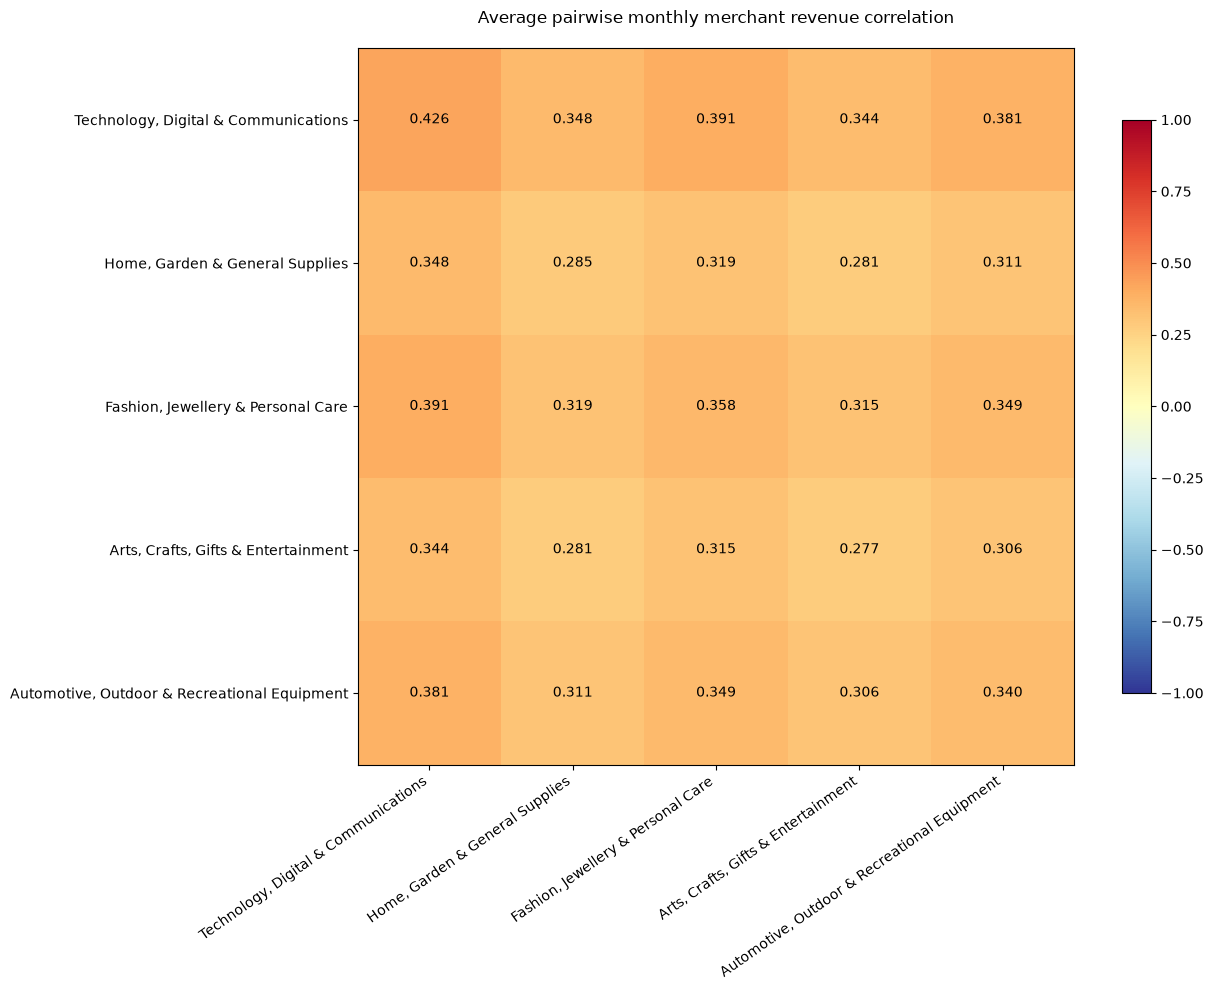

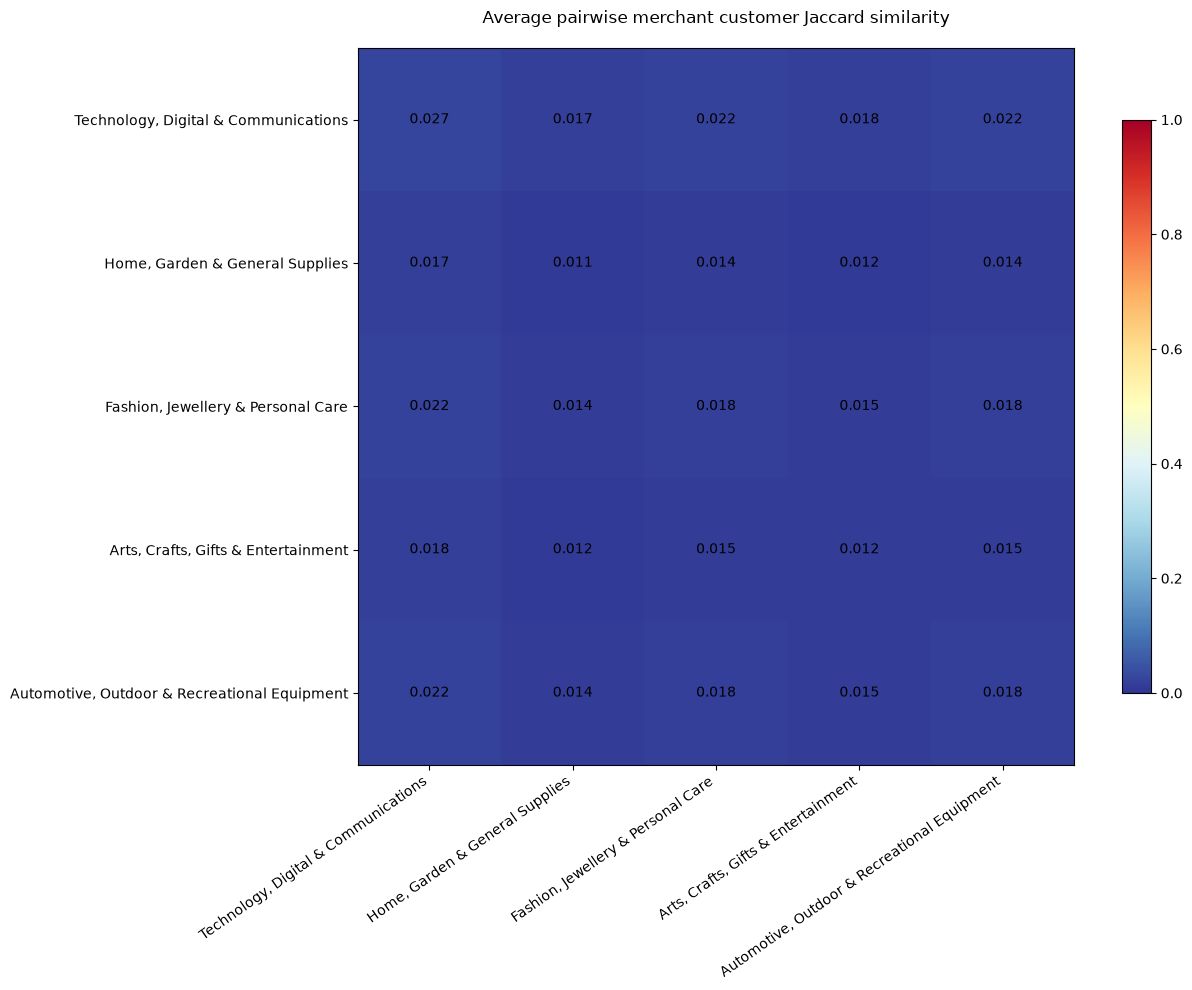

Saved similarity matrices, diagnostics, and heatmaps to: /Users/karkar/Desktop/Folder/2026/Applied Data Science/Project 2/industry-project-group-19/tables/analysis/merchant_similarity


In [23]:
similarity_output = root / "tables" / "analysis" / "merchant_similarity"
similarity_output.mkdir(parents=True, exist_ok=True)
correlation_revenue.to_csv(similarity_output / "correlation_revenue.csv", index_label="segment")
correlation_customers.to_csv(similarity_output / "correlation_customers.csv", index_label="segment")
revenue_pair_diagnostics.to_csv(similarity_output / "correlation_revenue_pair_diagnostics.csv", index=False)
customer_pair_diagnostics.to_csv(similarity_output / "correlation_customers_pair_diagnostics.csv", index=False)
save_similarity_heatmap(correlation_revenue, "Average pairwise monthly merchant revenue correlation", similarity_output / "correlation_revenue.png", (-1, 1))
save_similarity_heatmap(correlation_customers, "Average pairwise merchant customer Jaccard similarity", similarity_output / "correlation_customers.png", (0, 1))
print(f"Saved similarity matrices, diagnostics, and heatmaps to: {similarity_output}")
